<div style="background: linear-gradient(120deg, #102a43 0%, #176b87 52%, #2a9d8f 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 5px 20px rgba(16,42,67,0.28);">
    <img src='Figures/iteso.png' style="height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0; box-shadow: 0 2px 8px rgba(0,0,0,0.22);"/>
    <div style="border-left: 2px solid rgba(255,255,255,0.45); padding-left: 28px;">
        <h1 style="margin: 0 0 8px 0; color: white; font-size: 1.5em; line-height: 1.3; letter-spacing: 0.01em;">Examen Primer Parcial Versión A</h1>
        <h3 style="margin: 0 0 8px 0; color: rgba(255,255,255,0.86); font-weight: normal; font-size: 1.05em;">Laboratorio de Procesamiento de Datos</h3>
        <div style="color: rgba(255,255,255,0.78); font-size: 0.95em;">Fecha: 01/10/2026</div>
    </div>
</div>


<div style="border-left: 4px solid #176b87; padding: 14px 18px; margin: 8px 0 18px 0;">
    <strong style="color: #102a43;">Nombre del alumno: Matías Martínez Cabrera</strong>
    <span> </span>
</div>



### Instrucciones
1. Resuelve los **3 ejercicios** en este notebook. Agrega las celdas de código y de texto que necesites.
2. Todos los archivos están en la carpeta `datos/` junto a este notebook. Usa las variables `DATOS` y `SALIDA` que son generadas en la primera celda de código abajo.
3. **Nota:** El notebook debe ejecutarse completo con *Restart & Run All* sin errores.


In [1]:
# Configuración (no modificar)
import os
import re
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATOS = "datos"
SALIDA = "salidas"
os.makedirs(SALIDA, exist_ok=True)
print(sorted(os.listdir(DATOS)))


['exoplanetas.csv', 'niebla_unamuno.txt', 'tipos_cambio_bce.xml', 'titanic.csv']


---
## Ejercicio 1:  Extracción de Datos de Diferentes fuentes (30 pts)

**Parte A: Texto plano: `niebla_unamuno.txt`**

El archivo es la novela *Niebla* descargada de Project Gutenberg. Incluye un encabezado y un pie de licencia en inglés que **no** forman parte de la obra.

1. (4 pts) Lee el archivo con `open(..., encoding="utf-8")` dentro de un `with`. Conserva **solo** el texto entre las marcas `*** START OF ...` y `*** END OF ...`. Reporta el número de caracteres y de líneas antes y después del recorte.
2. (5 pts) Los capítulos inician con una línea que contiene solo un número romano (`I`, `II`, …). Cuenta cuántos capítulos tiene la novela.
3. (5 pts) Normaliza el texto (minúsculas, solo letras incluyendo acentos y `ñ`) y construye un `DataFrame` con las **15 palabras más frecuentes** de longitud ≥ 5 (columnas `palabra`, `frecuencia`). ¿Cuántas veces aparecen `augusto` y `eugenia`?
4. (4 pts) Guarda el resultado como `salidas/top_palabras_niebla.csv` **sin índice**.

**Parte B:  XML con espacios de nombres: `tipos_cambio_bce.xml`**

El Banco Central Europeo publica el valor de 1 euro en otras monedas. La estructura es `<Cube time="...">` → `<Cube currency="..." rate="..."/>`.

5. (6 pts) Con `xml.etree.ElementTree` recorre el árbol (atención al *namespace* `http://www.ecb.int/vocabulary/2002-08-01/eurofxref`) y construye un `DataFrame` con nombre **largo** que contenga columnas `fecha`, `moneda` y `tasa`. Convierte `tasa` al tipo de dato `float` y `fecha` al tipo de dato `datetime` usando el método de pandas: `pd.to_datetime`.
6. (6 pts) Usando el dataframe generado grafica la evolución en el tiempo del valor de 1 euro a `MXN` en una primera gráfica y el valor de 1 euro a `USD` en una segunda. ¿Cuántos días hábiles y cuántas monedas hay?


In [2]:
# 1 leer archivo
ruta_niebla = os.path.join(DATOS, "niebla_unamuno.txt")

with open(ruta_niebla, "r", encoding="utf-8") as f:
    lineas_originales = f.readlines()
    texto_original = "".join(lineas_originales)

caracteres_antes = len(texto_original)
lineas_antes = len(lineas_originales)
inicio_idx = texto_original.find("*** START OF")  # marcas
inicio_recorte = texto_original.find("\n", inicio_idx) + 1 
fin_recorte = texto_original.find("*** END OF")
texto_recortado = texto_original[inicio_recorte:fin_recorte]
lineas_recortadas = texto_recortado.split("\n")
caracteres_despues = len(texto_recortado)
lineas_despues = len(lineas_recortadas)
print(f"Antes del recorte había {caracteres_antes} caracteres, {lineas_antes} líneas.")
print(f"Después del recorte hay {caracteres_despues} caracteres, {lineas_despues} líneas.")

# 2 contar capítulos
regex_romanos = re.compile(r"^\s*[IVXLCDM]+\s*$") # un número nomás
capitulos = [linea for linea in lineas_recortadas if regex_romanos.match(linea) and linea.strip() != ""]
num_capitulos = len(capitulos)
print(f"Número de capítulos {num_capitulos}")

# 3 normalizar texto
texto_norm = texto_recortado.lower()
palabras = re.findall(r'[a-záéíóúüñ]+', texto_norm)
palabras_mayores_5 = [p for p in palabras if len(p) >= 5] #palabras que más se repiten
conteo = pd.Series(palabras_mayores_5).value_counts().reset_index()
conteo.columns = ['palabra', 'frecuencia']
top_15_palabras = conteo.head(15)
frec_augusto = conteo.loc[conteo['palabra'] == 'augusto', 'frecuencia'].values[0]
frec_eugenia = conteo.loc[conteo['palabra'] == 'eugenia', 'frecuencia'].values[0]
print(top_15_palabras)
print(f"\naugusto aparece {frec_augusto}")
print(f"eugenia aparece {frec_eugenia}")

# 4 guardar archivo
ruta_csv = os.path.join(SALIDA, "top_palabras_niebla.csv")
top_15_palabras.to_csv(ruta_csv, index=False)

Antes del recorte había 339189 caracteres, 8708 líneas.
Después del recorte hay 319683 caracteres, 8328 líneas.
Número de capítulos 33
    palabra  frecuencia
0     usted         376
1   augusto         372
2   eugenia         233
3     mujer         188
4    hombre         150
5     ahora         136
6    cuando         132
7    porque         113
8     mismo         106
9     sobre          94
10    pobre          92
11    había          90
12    tiene          82
13    luego          79
14    cosas          79

augusto aparece 372
eugenia aparece 233


Días hábiles 65
Monedas distintas 29


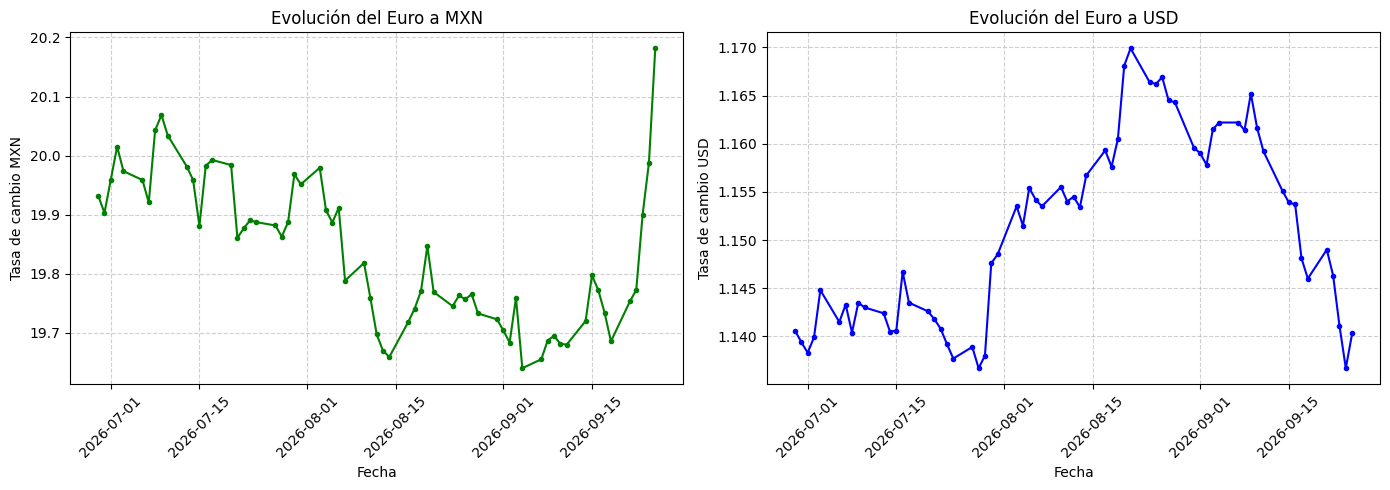

In [3]:
# Ejercicio 1 - Parte B

# 5
ruta_xml = os.path.join(DATOS, "tipos_cambio_bce.xml")
arbol = ET.parse(ruta_xml)
raiz = arbol.getroot()
ns = {'ecb': 'http://www.ecb.int/vocabulary/2002-08-01/eurofxref'} #espacio de nombres
datos_cambio = []

for nodo_tiempo in raiz.findall('.//ecb:Cube[@time]', ns):
    fecha_val = nodo_tiempo.attrib['time']
    for nodo_moneda in nodo_tiempo.findall('./ecb:Cube', ns):
        moneda_val = nodo_moneda.attrib['currency']
        tasa_val = nodo_moneda.attrib['rate']
        datos_cambio.append({'fecha': fecha_val, 'moneda': moneda_val, 'tasa': tasa_val})

df_tasas = pd.DataFrame(datos_cambio)
df_tasas['tasa'] = df_tasas['tasa'].astype(float)
df_tasas['fecha'] = pd.to_datetime(df_tasas['fecha'])
dias_habiles = df_tasas['fecha'].nunique()
num_monedas = df_tasas['moneda'].nunique()
print(f"Días hábiles {dias_habiles}")
print(f"Monedas distintas {num_monedas}")

# 6
df_mxn = df_tasas[df_tasas['moneda'] == 'MXN'].sort_values('fecha')
df_usd = df_tasas[df_tasas['moneda'] == 'USD'].sort_values('fecha')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Euro a MXN
ax1.plot(df_mxn['fecha'], df_mxn['tasa'], color='green', marker='.')
ax1.set_title('Evolución del Euro a MXN')
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Tasa de cambio MXN')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle='--', alpha=0.6)

# Euro a USD
ax2.plot(df_usd['fecha'], df_usd['tasa'], color='blue', marker='.')
ax2.set_title('Evolución del Euro a USD')
ax2.set_xlabel('Fecha')
ax2.set_ylabel('Tasa de cambio USD')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

---
## Ejercicio 2: Clasificación de tipos de datos (40 pts)

Usa `titanic.csv` (891 pasajeros).

1. (5 pts) Carga el archivo e inspecciona `shape`, `dtypes`, `head()` y `nunique()`. ¿Qué columnas numéricas son en realidad **categóricas**?
2. (10 pts) Completa la tabla (en Markdown) para: `survived`, `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `adult_male`, `deck`, `alone`.

   | Variable | Cualitativa / Cuantitativa | Subtipo (nominal, ordinal, binaria, discreta, continua) | Escala (nominal, ordinal, intervalo, razón) | Justificación breve |
   |---|---|---|---|---|

3. (5 pts) El dataset tiene **columnas redundantes** (la misma información codificada de dos formas). Identifica al menos tres pares y demuéstralo con `pd.crosstab`.
4. (10 pts) Escribe una función `clasificar_columna(serie, umbral_categorico=10)` que devuelva `"binaria"`, `"categorica"`, `"numerica_discreta"` o `"numerica_continua"` usando `dtype` y número de valores únicos. Aplícala a todas las columnas. ¿En qué columnas se equivoca y por qué?
5. (6 pts) Calcula la tasa de supervivencia global, por `sex`, por `class` y por la combinación `sex` × `class` (tabla dinámica). Presenta una gráfica de barras.
7. (4 pts) `age` tiene valores como `0.42` y `sibsp` solo enteros. Explica por qué una es continua y la otra discreta.

In [4]:
# Ejercicio 2

# 1
ruta_titanic = os.path.join(DATOS, "titanic.csv")
df_titanic = pd.read_csv(ruta_titanic)

print("shape ", df_titanic.shape)
print("----")
print("dtypes ", df_titanic.dtypes)
print("----")
display("head ",df_titanic.head())
print("----")
print("nunique ",df_titanic.nunique())

shape  (891, 15)
----
dtypes  survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object
----


'head '

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


----
nunique  survived         2
pclass           3
sex              2
age             88
sibsp            7
parch            7
fare           248
embarked         3
class            3
who              3
adult_male       2
deck             7
embark_town      3
alive            2
alone            2
dtype: int64


In [5]:
# survived y pclass son categóricas pero aparecen como enteros

**2**

| Variable | Cualitativa / Cuantitativa | Subtipo | Escala | Justificación |
| :--- | :--- | :--- | :--- | :--- |
| survived | Cualitativa | Binaria | Nominal | Solo admite dos categorías sin un orden |
| pclass | Cualitativa | Ordinal | Ordinal | Categorías jerarquía |
| sex | Cualitativa | Binaria | Nominal | Dos categorías descriptivas |
| age | Cuantitativa | Continua | Razón | Medida de tiempo que acepta decimales y tiene cero absoluto |
| sibsp | Cuantitativa | Discreta | Razón | Conteo de personas y solo admite enteros |
| parch | Cuantitativa | Discreta | Razón | Conteo de personas y solo admite enteros |
| fare | Cuantitativa | Continua | Razón | Precio con decimales y cero absoluto cuando el boleto fue gratis |
| embarked | Cualitativa | Nominal | Nominal | Letras de puertos sin orden o jerarquía |
| who | Cualitativa | Nominal | Nominal | Clasificación descriptiva sin orden  |
| adult_male| Cualitativa | Binaria | Nominal | Variable booleana |
| deck | Cualitativa | Nominal | Nominal | Letras que representan las cubiertas del barco |
| alone | Cualitativa | Binaria | Nominal | Variable booleana |

In [6]:
# 3

# survived y alive
display(pd.crosstab(df_titanic['survived'], df_titanic['alive']))
# pclass y class
display(pd.crosstab(df_titanic['pclass'], df_titanic['class']))
# embarked y embark_town
display(pd.crosstab(df_titanic['embarked'], df_titanic['embark_town']))

alive,no,yes
survived,,
0,549,0
1,0,342


class,First,Second,Third
pclass,,,
1,216,0,0
2,0,184,0
3,0,0,491


embark_town,Cherbourg,Queenstown,Southampton
embarked,,,
C,168,0,0
Q,0,77,0
S,0,0,644


In [7]:
# 4
def clasificar_columna(serie, umbral_categorico=10):
    n_unicos = serie.nunique()
    if n_unicos == 2:
        return "binaria"
    elif n_unicos < umbral_categorico:
        return "categorica"
    elif pd.api.types.is_numeric_dtype(serie):
        if pd.api.types.is_float_dtype(serie):
            return "numerica_continua"
        else:
            return "numerica_discreta"
    else:
        return "categorica"

clasificaciones = {col: clasificar_columna(df_titanic[col]) for col in df_titanic.columns}
for col, clasificacion in clasificaciones.items():
    print(f"{col:<12} {clasificacion}")

survived     binaria
pclass       categorica
sex          binaria
age          numerica_continua
sibsp        categorica
parch        categorica
fare         numerica_continua
embarked     categorica
class        categorica
who          categorica
adult_male   binaria
deck         categorica
embark_town  categorica
alive        binaria
alone        binaria


In [8]:
# ¿En qué columnas se equivoca?
# La función se equivoca en las columnas sibsp y parch
# Las clasifica como categorica porque tienen menos de 10 valores únicos
# Pero son variables numerica_discreta, ya que representan conteos matemáticos (cantidad de familiares).

Tasa de supervivencia global 38.38%

Tasa de supervivencia por sexo


sex
female    0.742038
male      0.188908
Name: survived, dtype: float64


Tasa de supervivencia por class


class
First     0.629630
Second    0.472826
Third     0.242363
Name: survived, dtype: float64


Tasa de supervivencia por sex x class


class,First,Second,Third
sex,,,
female,0.968085,0.921053,0.500000
male,0.368852,0.157407,0.135447


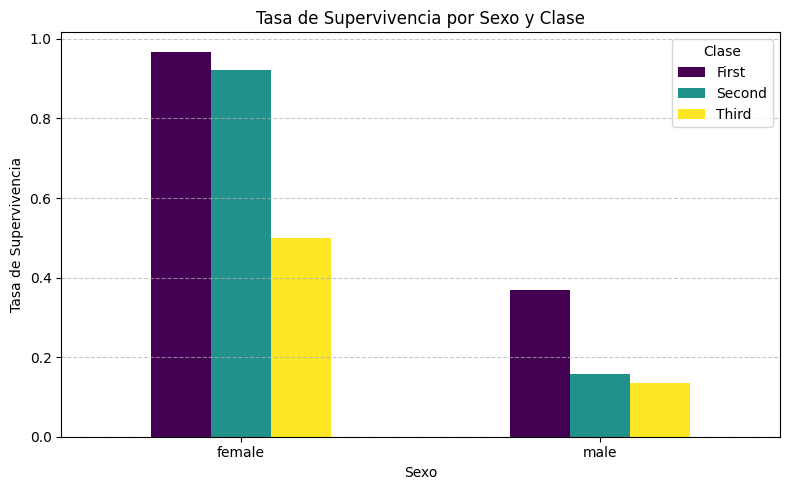

In [9]:
# 5
tasa_global = df_titanic['survived'].mean()
print(f"Tasa de supervivencia global {tasa_global:.2%}\n")

print("Tasa de supervivencia por sexo")
display(df_titanic.groupby('sex')['survived'].mean())
print("\nTasa de supervivencia por class")
display(df_titanic.groupby('class')['survived'].mean())

print("\nTasa de supervivencia por sex x class")
tabla_dinamica = df_titanic.pivot_table(index='sex', columns='class', values='survived', aggfunc='mean')
display(tabla_dinamica)

plt.figure(figsize=(8, 5))
tabla_dinamica.plot(kind='bar', ax=plt.gca(), colormap='viridis')
plt.title('Tasa de Supervivencia por Sexo y Clase')
plt.xlabel('Sexo')
plt.ylabel('Tasa de Supervivencia')
plt.xticks(rotation=0)
plt.legend(title='Clase')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [10]:
# 6 ¿Por qué age es continua y sibsp discreta?
# age: la edad es continua, porque existen muchos valores entre cada edad. 0.42 es lo que lleva de año 
# sibsp: representa un conteo de personas. Las personas son enteras, por eso para contaralas usamos números enteros

---
## Ejercicio 3 · Datos faltantes y atípicos (30 pts)

Usa el dataser `exoplanetas.csv`: que contiene información de planetas fuera del sistema solar. En las columnas puedes encontrar el método de descubrimiento (`method`), número de planetas del sistema (`number`), periodo orbital en días, masa (en masas de Júpiter), distancia (parsecs) y año.

**Faltantes**

1. (10 pts) Construye un reporte de calidad de datos con tipo de dato, conteo de faltantes, % de faltantes y número de valores únicos por columna, ordenado por % de faltantes.
2. (5 pts) Calcula el % de faltantes de `mass` **por `method`** (usa una agrupación por 'method'). 


**Atípicos**

4. (5 pts) Sobre `orbital_period` (sin tomar en cuenta los datos faltantes) detecta atípicos con **IQR** (1.5·IQR) y con **Z‑score** (|z| > 3). Reporta límites, número y % de atípicos. 
5. (10 pts)  Calcula el logaritmo en base 10 de `orbital_period` (con np.log10(`orbital_period`)) y vuelve a detectar los datos atípicos con **IQR** o **Z-Score**. Muestra histogramas de `orbital_period` y de su logaritmo. ¿Por qué  cres que cambian tanto los atípicos tras la transformación?

In [11]:
# Ejercicio 3 - Faltantes
ruta_exoplanetas = os.path.join(DATOS, "exoplanetas.csv")
df_exo = pd.read_csv(ruta_exoplanetas)

# 1 reporte
reporte_calidad = pd.DataFrame({
    'tipo de dato': df_exo.dtypes,
    'conteo de faltantes': df_exo.isnull().sum(),
    'porcentaje de faltantes': (df_exo.isnull().sum() / len(df_exo)) * 100,
    'valores unicos': df_exo.nunique()
}).sort_values('porcentaje de faltantes', ascending=False)

display(reporte_calidad)

# 2 porcentaje de faltantes
pct_faltantes_mass_por_method = df_exo['mass'].isnull().groupby(df_exo['method']).mean() * 100
display(pct_faltantes_mass_por_method.to_frame(name="porcebtaje de faltantes "))

,tipo de dato,conteo de faltantes,porcentaje de faltantes,valores unicos
mass,float64,522,50.434783,381
distance,float64,227,21.932367,552
orbital_period,float64,43,4.154589,988
method,str,0,0.000000,10
number,int64,0,0.000000,7
year,int64,0,0.000000,23


,porcebtaje de faltantes
method,
Astrometry,100.000000
Eclipse Timing Variations,77.777778
Imaging,100.000000
Microlensing,100.000000
Orbital Brightness Modulation,100.000000
Pulsar Timing,100.000000
Pulsation Timing Variations,100.000000
Radial Velocity,7.775769
Transit,99.748111


IQR     Límites [-775.40, 1306.85] | Número 126 | Porcentaje 12.70%
Z-Score Límites [-76041.27, 80047.10] | Número 3 | Porcentaje 0.30%
Log10 IQR Límites [-2.24, 5.70] | Número 1 | Porcentaje 0.10%


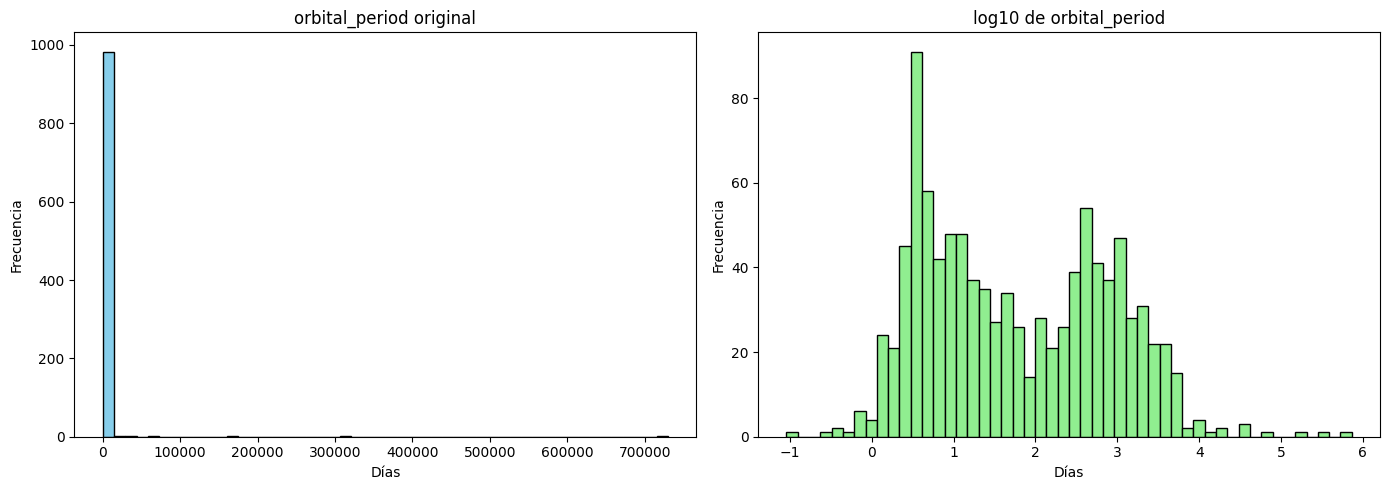

In [12]:
# Ejercicio 3 - Atípicos
orbital_period = df_exo['orbital_period'].dropna() # sin faltantes

# 4
# iqr
Q1 = orbital_period.quantile(0.25)
Q3 = orbital_period.quantile(0.75)
IQR = Q3 - Q1
lim_inf_iqr = Q1 - 1.5 * IQR
lim_sup_iqr = Q3 + 1.5 * IQR
atipicos_iqr = orbital_period[(orbital_period < lim_inf_iqr) | (orbital_period > lim_sup_iqr)]
n_atipicos_iqr = len(atipicos_iqr)
pct_atipicos_iqr = (n_atipicos_iqr / len(orbital_period)) * 100

# z-score
media = orbital_period.mean()
desviacion = orbital_period.std()
lim_inf_z = media - 3 * desviacion
lim_sup_z = media + 3 * desviacion
z_scores = (orbital_period - media) / desviacion
atipicos_z = orbital_period[np.abs(z_scores) > 3]
n_atipicos_z = len(atipicos_z)
pct_atipicos_z = (n_atipicos_z / len(orbital_period)) * 100
print(f"IQR     Límites [{lim_inf_iqr:.2f}, {lim_sup_iqr:.2f}] | Número {n_atipicos_iqr} | Porcentaje {pct_atipicos_iqr:.2f}%")
print(f"Z-Score Límites [{lim_inf_z:.2f}, {lim_sup_z:.2f}] | Número {n_atipicos_z} | Porcentaje {pct_atipicos_z:.2f}%")

# 5
op_log = np.log10(orbital_period)
Q1_log = op_log.quantile(0.25)
Q3_log = op_log.quantile(0.75)
IQR_log = Q3_log - Q1_log
lim_inf_log = Q1_log - 1.5 * IQR_log
lim_sup_log = Q3_log + 1.5 * IQR_log
atipicos_log_iqr = op_log[(op_log < lim_inf_log) | (op_log > lim_sup_log)]

# atípicos 
print(f"Log10 IQR Límites [{lim_inf_log:.2f}, {lim_sup_log:.2f}] | Número {len(atipicos_log_iqr)} | Porcentaje {(len(atipicos_log_iqr) / len(op_log)) * 100:.2f}%")

# Histogramas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
# original
ax1.hist(orbital_period, bins=50, color='skyblue', edgecolor='black')
ax1.set_title('orbital_period original')
ax1.set_xlabel('Días')
ax1.set_ylabel('Frecuencia')
# logarítmico
ax2.hist(op_log, bins=50, color='lightgreen', edgecolor='black')
ax2.set_title('log10 de orbital_period')
ax2.set_xlabel('Días')
ax2.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [13]:
# ¿Por qué crees que cambian tanto los atípicos tras la transformación?

# Los datos tienen una distribución muy asimétrica, la mayoria son periodos cortos, pero hay algunos muy largos
# por eso el z-score o el IQR marcan muchos datos del extremo superior como atípicos.
# Al usar el logaritmo comprimimos la escala de los valores grandes, por eso ya se ven como una distribucion normal 
# así ya se pueden usar iqr y Z-score y ya no toma atípicos incorrectos.
